# Solutions

In [1]:
import numpy as np
import scipy.linalg
import scipy.special
import matplotlib.pyplot as plt

## DFT Part 1 - Diffusion in 2D

In [2]:
def gaussian(x, y, x0, t):
    # Green's function for the diffusion equation
    dx = x-x0[0]
    dy = y-x0[1]
    return np.exp(-(dx**2 + dy**2)/(4*t)) / (4*np.pi*t)

First set up a Gaussian profile, take a look at the DFT, and make sure we can reconstruct the original profile with an inverse transform:

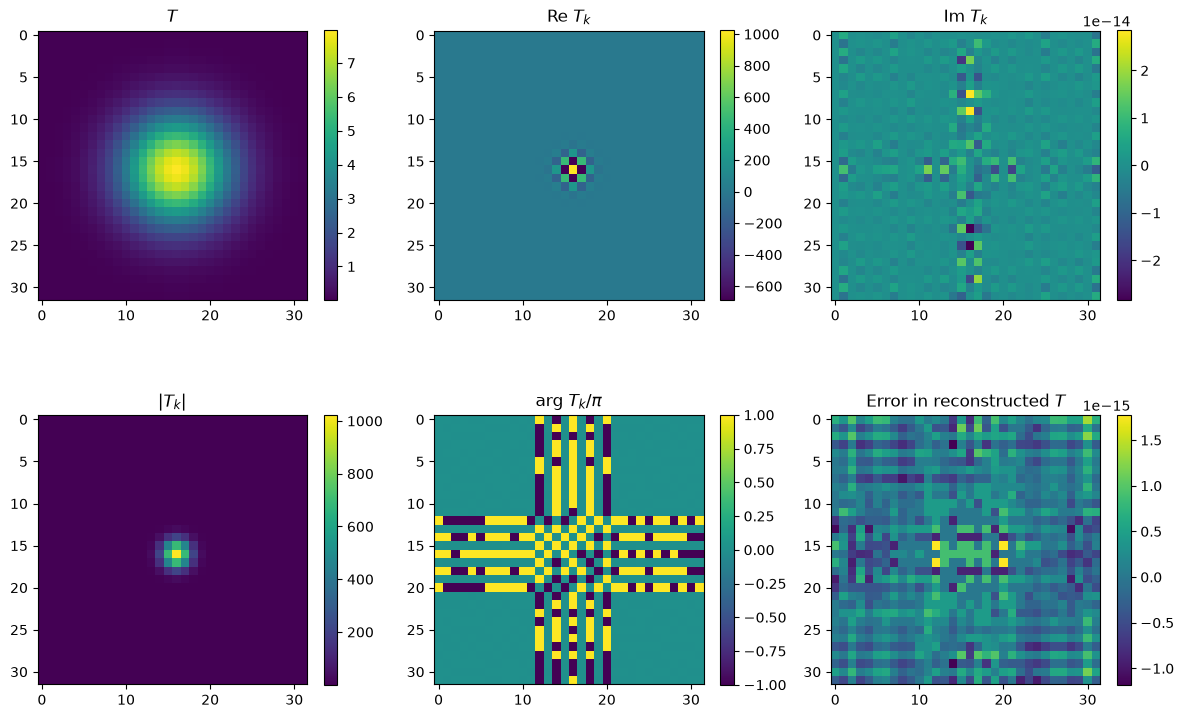

kx shape= (32,)
kx values= [ 0.       0.03125  0.0625   0.09375  0.125    0.15625  0.1875   0.21875
  0.25     0.28125  0.3125   0.34375  0.375    0.40625  0.4375   0.46875
 -0.5     -0.46875 -0.4375  -0.40625 -0.375   -0.34375 -0.3125  -0.28125
 -0.25    -0.21875 -0.1875  -0.15625 -0.125   -0.09375 -0.0625  -0.03125]
0.03125 0.0625 0.09375 0.46875


In [3]:
# set up the grid and initial condition
# we set T to be the Green's function corresponding to time t0
# Use a fairly small grid so we can see what's happening with the FFTs
n = 32
T = np.zeros((n,n))
x = np.linspace(0,1,n,endpoint=False)
dx = x[1]-x[0]
xx, yy = np.meshgrid(x, x)
x0 = (0.5,0.5)
t0 = 0.01 # initial time
T = gaussian(xx, yy, x0, t0)

# Find the 2D FFT of the temperature field
Tk = np.fft.fft2(T)
# shifted version with k=0 at the center
Tkshift = np.fft.fftshift(Tk)

# Plot the FFT
fig = plt.figure(figsize=(12,8))
plt.subplot(231)
plt.imshow(T)
plt.title(r'$T$')
shrink = 0.7
plt.colorbar(shrink=shrink)

plt.subplot(232)
plt.imshow(Tkshift.real)
plt.title(r'Re $T_k$')
plt.colorbar(shrink=shrink)

plt.subplot(233)
plt.imshow(Tkshift.imag)
plt.title(r'Im $T_k$')
plt.colorbar(shrink=shrink)

plt.subplot(234)
plt.imshow(np.absolute(Tkshift))
plt.title(r'$|T_k|$')
plt.colorbar(shrink=shrink)

plt.subplot(235)
plt.imshow(np.angle(Tkshift)/np.pi)
#plt.imshow(np.arctan2(Tkshift.imag, Tkshift.real))
plt.title(r'arg $T_k/\pi$')
plt.colorbar(shrink=shrink)

plt.subplot(236)
T2 = np.fft.ifft2(Tk)
plt.imshow(T2.real-T)
plt.title(r'Error in reconstructed $T$')
plt.colorbar(shrink=shrink)

plt.tight_layout()
plt.show()

# Have a look at the k vectors
kx = np.fft.fftfreq(n)
ky = np.fft.fftfreq(n)
kxx, kyy = np.meshgrid(kx, ky)

print('kx shape=',np.shape(kx))
print('kx values=', kx)
print(1/n, 2/n, 3/n, 0.5 - 1/n)

Notice that the Fourier transform is purely real (the imaginary part is near floating point precision). This makes sense because the Gaussian is centred, so only the cosine terms (even) should be active, no sine terms (odd).

When we calculate the argument of the imaginary number, we're seeing noise basically as the number switches from positive to negative: the values are either $\theta=0$ corresponding to $e^0 = +1$ or $\pm \pi$ corresponding to $e^{\pm \pi}=-1$.

Now evolve in time from `t0` to `t0+tevol`

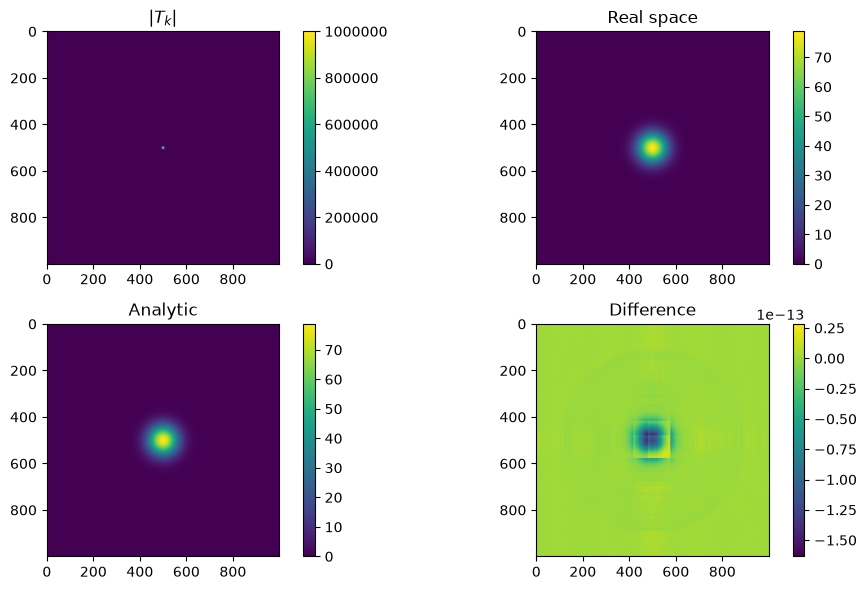

In [4]:
# set up the grid and initial condition
# we set T to be the Green's function corresponding to time t0
# Use a fairly small grid so we can see what's happening with the FFTs
n = 1000
T = np.zeros((n,n))
x = np.linspace(0,1,n,endpoint=False)
dx = x[1]-x[0]
xx, yy = np.meshgrid(x, x)
x0 = (0.5,0.5)
t0 = 1e-5 # initial time
tevol = 1e-3
T0 = gaussian(xx, yy, x0, t0)

# Find the 2D FFT of the temperature field
Tk = np.fft.fft2(T0)

# Evolve in time
kx = np.fft.fftfreq(n)
ky = np.fft.fftfreq(n)
kxx, kyy = np.meshgrid(kx, ky)
kxx *= 2*np.pi / dx
kyy *= 2*np.pi / dx
Tk = Tk * np.exp(-(kxx**2 + kyy**2)*tevol)

# shifted version with k=0 at the center
Tk = np.fft.fftshift(Tk)

# Analytic
T1 = gaussian(xx, yy, x0, t0+tevol)

# Plot |T_k|
fig = plt.figure(figsize=(10,6))
plt.subplot(221)
plt.imshow(np.absolute(Tk))
plt.title(r'$|T_k|$')
shrink = 1
plt.colorbar(shrink=shrink)

# Plot the inverse transform
plt.subplot(222)
T2 = np.fft.ifft2(Tk)
#T2max = np.max(np.abs(T2))
plt.imshow(np.abs(T2))
plt.title(r'Real space')
plt.colorbar(shrink=shrink)

plt.subplot(223)
plt.imshow(np.abs(T1))#/np.max(np.abs(T)))
plt.title(r'Analytic')
plt.colorbar(shrink=shrink)

plt.subplot(224)
plt.title(r'Difference')
plt.imshow(np.abs(T2)-T1)
#plt.imshow(np.abs(T2)/T2max-T/np.max(T))
plt.colorbar(shrink=shrink)

plt.tight_layout()
plt.show()

Time sequence

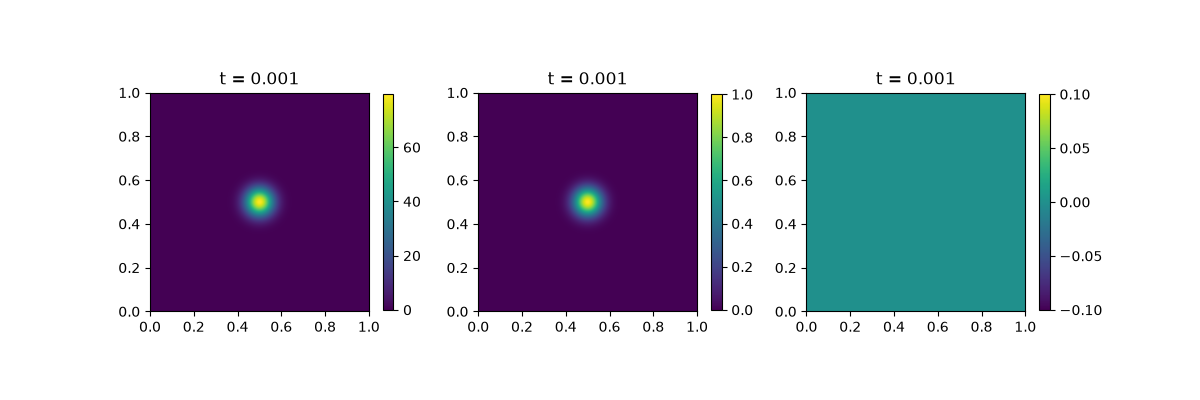

In [5]:
%matplotlib widget
from matplotlib.animation import FuncAnimation

# set up the grid and initial condition
n = 1000
x = np.linspace(0,1,n,endpoint=False)
dx = x[1]-x[0]
xx, yy = np.meshgrid(x, x)

x0 = (0.5, 0.5)
t0 = 1e-3
dt = 1e-4

T0 = gaussian(xx, yy, x0, t0)

# Find the 2D FFT of the temperature field
Tk0 = np.fft.fft2(T0)
kx = np.fft.fftfreq(n)
ky = np.fft.fftfreq(n)
kxx, kyy = np.meshgrid(kx, ky)
kxx *= 2*np.pi / dx
kyy *= 2*np.pi / dx

# Set up the figure
plt.clf()
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
im0 = ax[0].imshow(T0, origin='lower', extent=[0, 1, 0, 1])
plt.colorbar(im0, ax=ax[0], shrink=0.7)
title0 = ax[0].set_title(f't = {t0:.4g}')
im1 = ax[1].imshow(T0/np.max(T0), origin='lower', extent=[0, 1, 0, 1])
plt.colorbar(im1, ax=ax[1], shrink=0.7)
title1 = ax[1].set_title(f't = {t0:.4g}')
err = T0-gaussian(xx,yy,x0,t0)
im2 = ax[2].imshow(err, origin='lower', extent=[0, 1, 0, 1])
plt.colorbar(im2, ax=ax[2], shrink=0.7)
errmax = np.max(np.abs(err))
im2.set_clim(-errmax, errmax)
title2 = ax[2].set_title(f't = {t0:.4g}')

# Animation update function
def update(frame):
    global Tk, kxx, kyy, dt,xx,yy,x0,t0

    Tk = Tk0 * np.exp(-(kxx**2 + kyy**2)*(frame+1)*dt)

    T = np.abs(np.fft.ifft2(Tk))
    im0.set_data(T)

    Tanalytic = gaussian(xx,yy,x0,t0+(frame+1)*dt)
    err = T - Tanalytic
    im2.set_data(err)
    errmax = np.max(np.abs(err))
    im2.set_clim(-errmax, errmax)

    T = T / np.max(T)
    im1.set_data(T)
        
    title0.set_text(f't = {t0 + (frame+1)*dt:.4g}')
    title1.set_text(f't = {t0 + (frame+1)*dt:.4g}')
    title2.set_text(f't = {t0 + (frame+1)*dt:.4g}')

    return im0, im1, im2, title0, title1, title2
    
ani = FuncAnimation(fig, update, frames=100, interval=50, blit=False, repeat=False)

plt.show()

%matplotlib inline

## 1D DFTs

<Figure size 640x480 with 0 Axes>

<Figure size 1200x400 with 0 Axes>

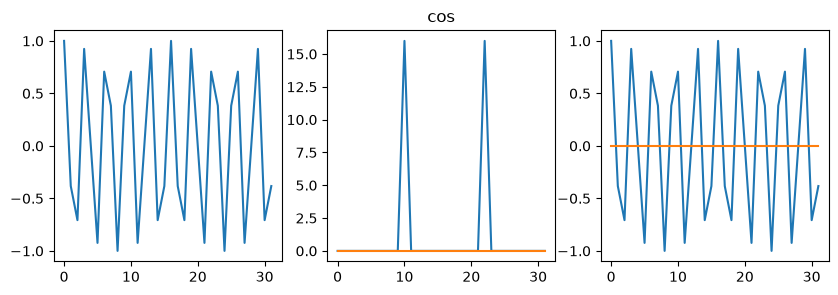

<Figure size 640x480 with 0 Axes>

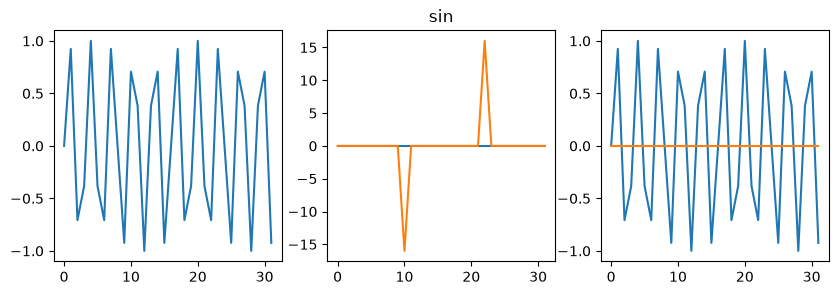

<Figure size 640x480 with 0 Axes>

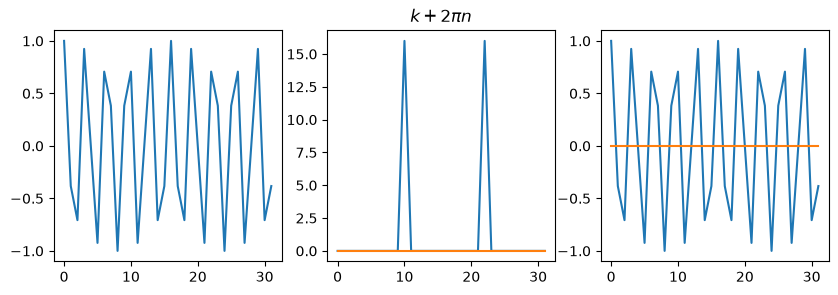

<Figure size 640x480 with 0 Axes>

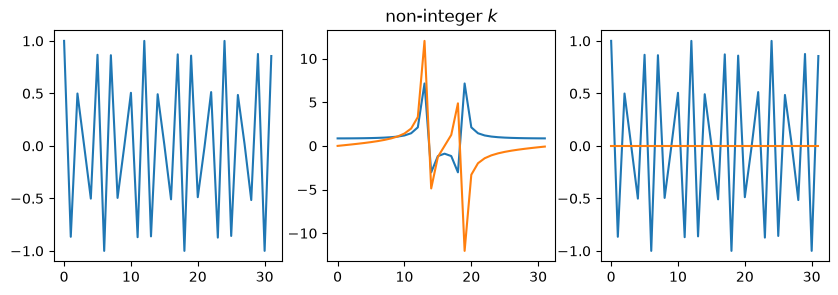

In [6]:
def do_plots(f,title=""):
    g = np.fft.fft(f)
    
    plt.clf()
    fig = plt.figure(figsize=(10,3))

    plt.subplot(131)
    plt.plot(x, f)

    plt.subplot(132)
    plt.plot(x, np.real(g))
    plt.plot(x, np.imag(g))
    plt.title(title)

    plt.subplot(133)
    h = np.fft.ifft(g)
    plt.plot(x, np.real(h))
    plt.plot(x, np.imag(h))

    plt.show()


# Question 1
# Look at sin(kx) and cos(kx)

n = 32
x = np.linspace(0,n-1,n)
dx = x[1]-x[0]

k = 2*np.pi * (10/n)
do_plots(np.cos(k*x),title='cos')

do_plots(np.sin(k*x),title='sin')

# when we add n to the frequency, we get the same answer
# the result is aliased back into our range
k = 2*np.pi * (10/n + n)
do_plots(np.cos(k*x), title=r'$k+2\pi n$')

# a non-integer frequency gives leakage into other bins
# the discontinuity at the boundaries leads to high freq components
k = 2*np.pi * 13.33/n
do_plots(np.cos(k*x), title=r'non-integer $k$')

<Figure size 640x480 with 0 Axes>

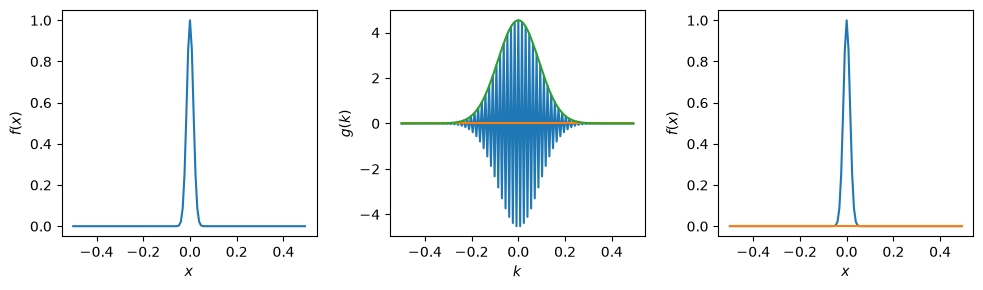

Parseval check: 3.208484191527739 3.208484191527738 8.881784197001252e-16


Text(0, 0.5, 'Im $g(k)$')

<Figure size 640x480 with 0 Axes>

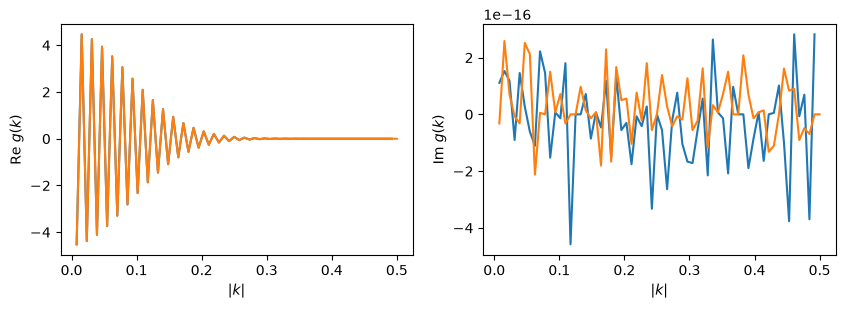

In [7]:
%matplotlib inline
plt.clf()

# Gaussian
n = 128
x = np.linspace(-0.5,0.5,n,endpoint=False)
dx = x[1]-x[0]

f = np.exp(-(x-0)**2/(0.02**2))
g = np.fft.fft(f)

fig = plt.figure(figsize=(10,3))

plt.subplot(131)
plt.plot(x, f)
plt.xlabel(r'$x$')
plt.ylabel(r'$f(x)$')

plt.subplot(132)
k = np.fft.fftfreq(n)
gs = np.fft.fftshift(g)
ks = np.fft.fftshift(k)
plt.plot(ks, np.real(gs))
plt.plot(ks, np.imag(gs))
plt.plot(ks, np.abs(gs))
plt.xlabel(r'$k$')
plt.ylabel(r'$g(k)$')

plt.subplot(133)
# Check the inverse transform
h = np.fft.ifft(g)
plt.plot(x, np.real(h))
plt.plot(x, np.imag(h))
plt.xlabel(r'$x$')
plt.ylabel(r'$f(x)$')

plt.tight_layout()
plt.show()

# Check Parseval's theorem
sumf = np.sum(np.abs(f)**2)
sumg = np.sum(np.abs(g)**2)/n
print('Parseval check:', sumf, sumg, sumf-sumg)

plt.clf()
# This shows that the real part is symmetric about k=0
# but the imaginary part is anti-symmetric; therefore F(-k) = F^*(k)
fig = plt.figure(figsize=(10,3))
plt.subplot(121)
k = np.fft.fftfreq(n)
plt.plot(k[k>0], np.real(g[k>0]))
plt.plot(-k[k<0], np.real(g[k<0]))
plt.xlabel(r'$|k|$')
plt.ylabel(r'Re $g(k)$')

plt.subplot(122)
plt.plot(k[k>0], np.imag(g[k>0]))
plt.plot(-k[k<0], np.imag(g[k<0]))
plt.xlabel(r'$|k|$')
plt.ylabel(r'Im $g(k)$')


Here I've offset the Gaussian slightly from the centre so that the Fourier transform has real and imaginary parts. A centred Gaussian is an even function so the Fourier transform is then purely real. 

## Manipulating $f(x)$ in Fourier space

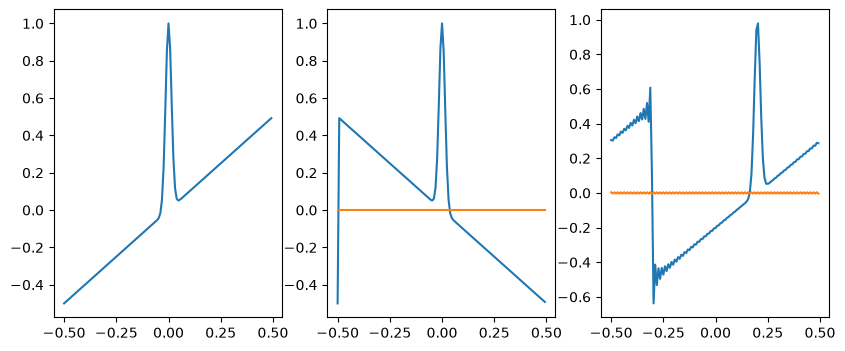

In [8]:
n = 128
x = np.linspace(-0.5,0.5,n,endpoint=False)
dx = x[1]-x[0]

f = np.exp(-(x-0)**2/(0.02**2)) + x
g = np.fft.fft(f)

fig = plt.figure(figsize=(10,4))

plt.subplot(131)
plt.plot(x, f)

plt.subplot(132)
# complex conjugate is equivalent to x->-x
h = np.fft.ifft(np.conjugate(g))
plt.plot(x, np.real(h))
plt.plot(x, np.imag(h))

plt.subplot(133)
# add a gradient in phase is equivalent to a translation in x
j = complex(0,1)
k = (2*np.pi/dx) * np.fft.fftfreq(n)
g = g * np.exp(-j * k * 0.2)

h = np.fft.ifft(g)
plt.plot(x, np.real(h))
plt.plot(x, np.imag(h))
plt.show()

## Convolution with DFT

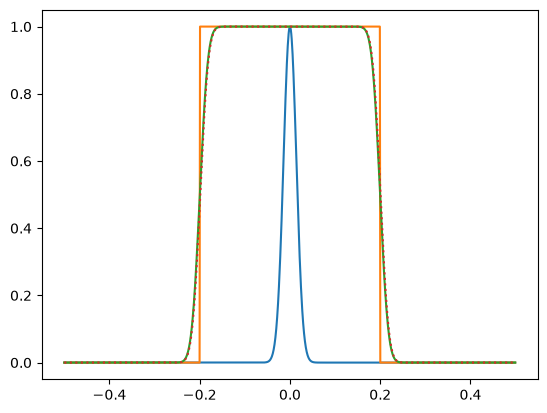

In [9]:
import scipy.signal

def convolution(f,g):
    ft = np.fft.fft(f)
    gt = np.fft.fft(g)
    return np.fft.ifft(ft*gt)

n = 1024
x = np.linspace(-0.5,0.5,n,endpoint=False)
dx = x[1]-x[0]

# Gaussian
f = np.exp(-(x)**2/(0.02**2))
# Top hat
g = np.zeros_like(x)
g[(x>-0.2)&(x<0.2)] = 1

plt.plot(x,f)
plt.plot(x,g)
h = convolution(g,f)
h = np.roll(h, n//2)  # shift the result to centre it
plt.plot(x,np.real(h)/np.max(np.real(h)))

# Compare against the scipy convolution function
h = scipy.signal.convolve(g,f, mode='same')
plt.plot(x,h/np.max(h),':')

## Red noise generator

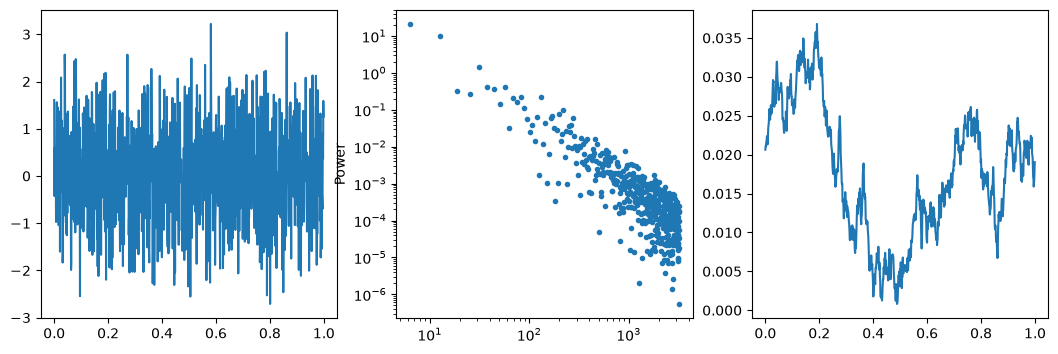

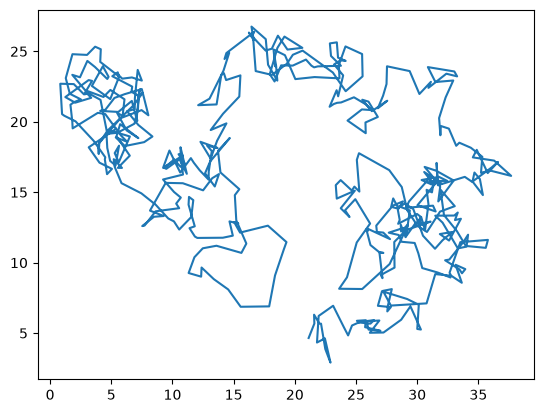

In [10]:
n = 1024
x = np.linspace(0,1,n,endpoint=False)
dx = x[1]-x[0]

f = np.random.randn(n)

g = np.fft.fft(f)

fig = plt.figure(figsize=(13,4))

plt.subplot(131)
plt.plot(x, f)

plt.subplot(132)
g2 = g.copy()
k = (2*np.pi/dx) * np.fft.fftfreq(n)
g2[1:] /= 1j*k[1:]

plt.plot(k[k>0], np.abs(g2[k>0])**2, '.')
plt.yscale('log')
plt.xscale('log')
plt.ylabel('Power')

plt.subplot(133)

h = np.fft.ifft(g2)
plt.plot(x, np.real(h))
#plt.plot(x, np.imag(h))

plt.show()

plt.clf()
plt.plot(np.real(h[:n//2])/dx, np.real(h[n//2:])/dx)
plt.show()

In this question, we generate a sample of red noise which has a power spectrum $1/k^2$ by taking the Fourier transform of white noise (flat power spectrum) and dividing the Fourier transorm by $ik$. This is equivalent to integrating the white noise, since

$$g(x) = \int^x dx^\prime f(x^\prime) = \int^x dx^\prime \int dk\ F(k)  e^{ikx^\prime} = \int dk\ F(k) \int^x dx^\prime  e^{ikx^\prime} = \int dk\ {F(k)\over ik} e^{ikx}.$$ 

When we take the samples of red noise and plot them, we see a random walk (you can see that the distance travelled is $\sim \sqrt{N}$ as expected). Individual steps in the random are uncorrelated (white noise) but because successive steps add up over time (integrate) we get a red noise spectrum in the end (i.e. you can think of the random walk as $dx/dt = f(t)$ where $f(t)$ is white noise; we need to integrate this to get $x(t)$).

This is an interesting way to generate a random walk.

## Advection

In [11]:
def do_integration(f_init, dt, n, dx, v, T, update = 'semi-implicit'):
    
    g = np.fft.fft(f_init)
    k = np.fft.fftfreq(n) * 2*np.pi/dx

    nsteps = int(T/dt)
    #dt = T/nsteps  # make sure we end at the required time t=T

    for i in range(nsteps):

        match update:
            case 'explicit':
                g = g * (1 - dt*1j*k*v)
            case 'implicit':
                g = g / (1 + dt*1j*k*v)
            case 'semi-implicit':
                g = g * (1 - 0.5*dt*1j*k*v) / (1 + 0.5*dt*1j*k*v)
                        
    return np.fft.ifft(g)

In [12]:
def plot_grid(T, alpha):
    # set up the grid
    n = 100
    x = np.linspace(0,1,n,endpoint=False)
    dx = x[1]-x[0]

    # velocity 1
    v = 1
    
    # timestep
    dt = alpha * dx/abs(v)

    updates = ['explicit', 'implicit', 'semi-implicit']

    plt.clf()
    plt.figure(figsize = (10,8))
    plt.suptitle('v=%lg, alpha=%lg' % (v, alpha))
    
    count = 0

    for update in updates:
    
        # Gaussian
        f_init = np.exp(-(x-0.5)**2/0.05**2)
        f = do_integration(f_init, dt, n, dx, v, T, update = update)
        plt.subplot(3,3,count*3 + 1)
        plt.plot(x, np.real(f_init), ":")
        plt.plot(x, np.real(f))
    
        # Step
        f_init = np.zeros_like(x)
        f_init[n//4:3*n//4] = 1
        f = do_integration(f_init, dt, n, dx, v, T, update = update)
        plt.subplot(3,3,count*3 + 2)
        plt.plot(x, np.real(f_init), ":")
        plt.plot(x, np.real(f))
        plt.title(update)

        # sin
        f_init = np.sin(2*np.pi*2*x)
        f = do_integration(f_init, dt, n, dx, v, T, update = update)
        plt.subplot(3,3,count*3 + 3)
        plt.plot(x, np.real(f_init), ":")
        plt.plot(x, np.real(f))

        count +=1
    
    plt.tight_layout()
    plt.show()

<Figure size 640x480 with 0 Axes>

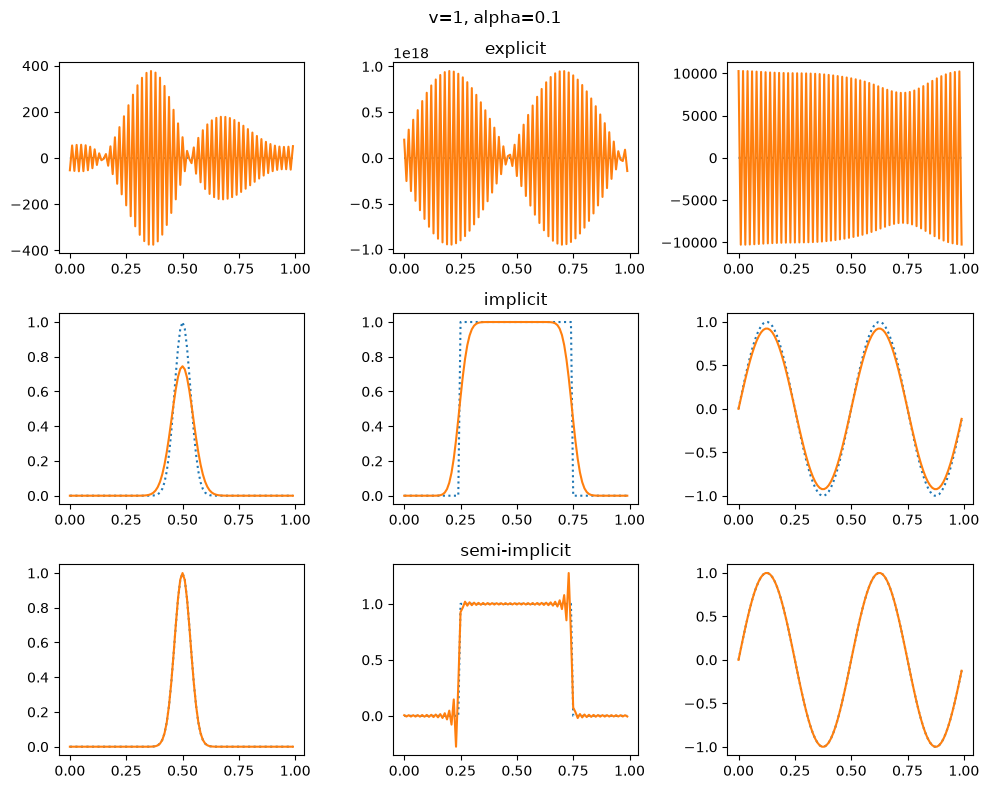

In [13]:
# parameters are: T, alpha
plot_grid(1.0, 0.1)

## Diffusion with Chebyshev

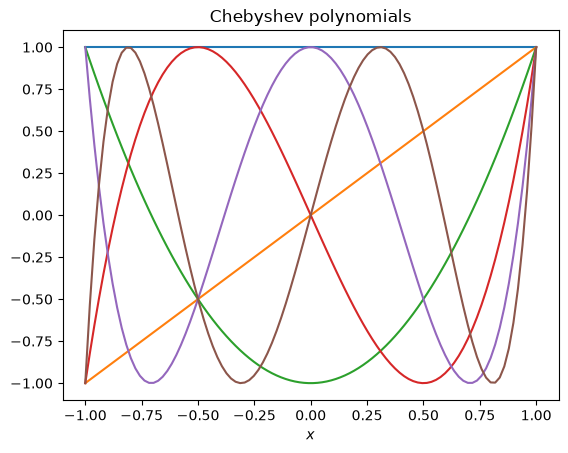

In [14]:
# Plot the Chebyshev polynomials
def plot_poly(poly_generator, title, num):
    for i in range(num):
        x = np.linspace(-1,1,100)
        a = np.zeros(num)
        a[i] = 1
        poly = poly_generator(a)
        plt.plot(x, poly(x))
    plt.xlabel(r'$x$')
    plt.title(title)
    plt.show()

plot_poly(np.polynomial.chebyshev.Chebyshev, 'Chebyshev polynomials', 6)

In [15]:
# Now check that we can differentiate these

# First construct a polynomial
a = np.array((0,0,0,0,0,0,1))
poly = np.polynomial.chebyshev.Chebyshev(a)
print('f(x) = ', poly)

# Differentiate it
b = np.polynomial.chebyshev.chebder(a, m=2)
poly2 = np.polynomial.chebyshev.Chebyshev(b)
print("f''(x) = ", poly2)

# Note that the differentiated polynomial has 
# two less coefficients than the one we started with
# because differentiated twice and lost the two highest
# powers of x

f(x) =  0.0 + 0.0·T₁(x) + 0.0·T₂(x) + 0.0·T₃(x) + 0.0·T₄(x) + 0.0·T₅(x) +
1.0·T₆(x)
f''(x) =  108.0 + 0.0·T₁(x) + 192.0·T₂(x) + 0.0·T₃(x) + 120.0·T₄(x)


In [16]:
def greens_unbounded(x, x0, t, D):
    # Green's function for the diffusion equation
    return np.exp(-(x-x0)**2/(4*D*t)) / np.sqrt(4*np.pi*D*t)

def greens(x, x0, t, D):
    # (Approximate) Green's function for the diffusion equation with zero boundary conditions at x=-1,+1
    # (using method of images)
    f = greens_unbounded(x, x0, t, D)
    f -= greens_unbounded(x, -(2+x0), t, D)
    f -= greens_unbounded(x, 2-x0, t, D)
    return f

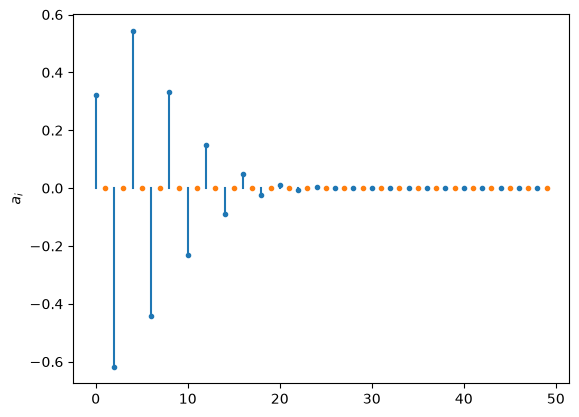

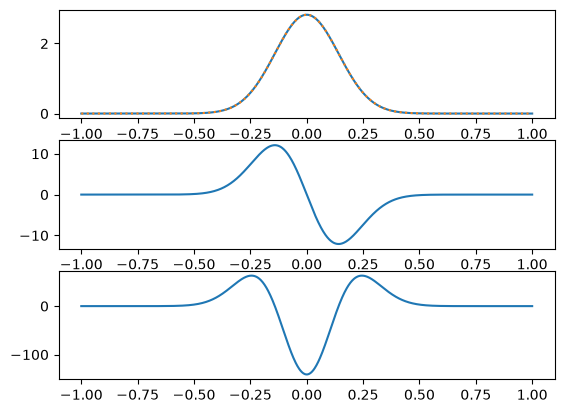

In [17]:
%matplotlib inline

# Fit a Chebyshev polynomial to the Green's function and check the derivatives
n = 1000
nmodes = 50
x = np.linspace(-1,1,n)
T = greens(x, 0.0, 0.01, 1)
a = np.polynomial.chebyshev.chebfit(x, T, nmodes-1)

ii = np.linspace(0,nmodes-1,nmodes)
ind = np.where(np.abs(a)>1e-14)[0]
plt.plot(ii[ind],a[ind],'C0.')
for j in ind:
    plt.plot(np.array([ii[j],ii[j]]),np.array([0,a[j]]),'C0')
ind = np.where(np.abs(a)<=1e-14)[0]
plt.plot(ii[ind],a[ind],'C1.')
for j in ind:
    plt.plot(np.array([ii[j],ii[j]]),np.array([0,a[j]]),'C1')
plt.ylabel(r'$a_i$')
plt.show()

plt.clf()
plt.subplot(311)
poly = np.polynomial.chebyshev.Chebyshev(a)
plt.plot(x, poly(x))
plt.plot(x,T,":")

plt.subplot(312)
poly1 = np.polynomial.chebyshev.Chebyshev(np.polynomial.chebyshev.chebder(a, m=1))
plt.plot(x, poly1(x))

plt.subplot(313)
poly2 = np.polynomial.chebyshev.Chebyshev(np.polynomial.chebyshev.chebder(a, m=2))
plt.plot(x, poly2(x))

plt.show()

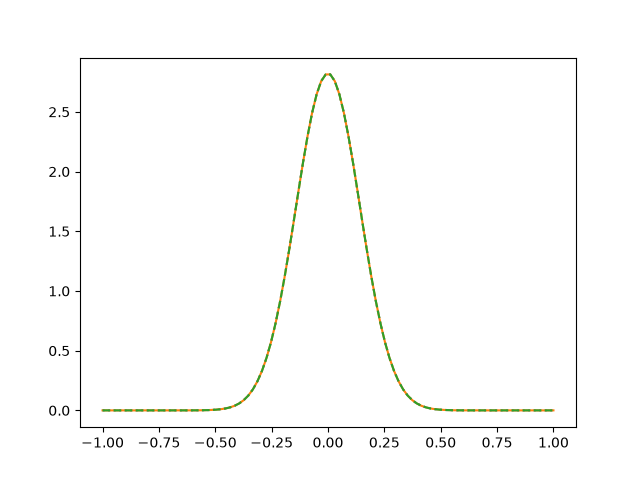

In [18]:
%matplotlib widget
from matplotlib.animation import FuncAnimation

def update(k):    
    global a, dt, t0, x, D2, AA, x0

    # time-update
    da = dt * np.polynomial.chebyshev.chebder(a, m=2)
    a[:-2] = a[:-2] + da

    # boundary condition
    a[-2] = -np.sum(a[:-2:2])
    a[-1] = -np.sum(a[1:-2:2])
    
    poly = np.polynomial.chebyshev.Chebyshev(a)
    dat.set_ydata(poly(x))
    t = t0 + (k+1)*dt
    dat2.set_ydata(greens(x, x0, t, 1))
    ax.set_title('t=%lg' % (t,))

    return dat, dat2
    
# initial condition
n = 100
x = np.linspace(-1,1,n,endpoint=True)
dx = x[1]-x[0]
t0 = 0.01
x0 = 0.0
Tinit = greens(x, x0, t0, 1)

tend = 1.1*t0
dt = 5e-6
niter = int((tend-t0)/dt)
dt = (tend-t0)/niter

n_mode = 32  # assumed to be even number
a = np.polynomial.chebyshev.chebfit(x, Tinit, n_mode-1)
a[-2] = -np.sum(a[:-1:2])   # sum of even coefficients
a[-1] = -np.sum(a[1:-2:2])  # sum of odd coefficients

# Initial plot
plt.close()
fig, ax = plt.subplots()
dat2, = ax.plot(x, Tinit, ':')
poly = np.polynomial.chebyshev.Chebyshev(a)
dat, = ax.plot(x, poly(x))
ax.plot(x, Tinit,'--')

ani = FuncAnimation(fig, update, frames=niter, interval=10, repeat=False)

Implicit time integration:

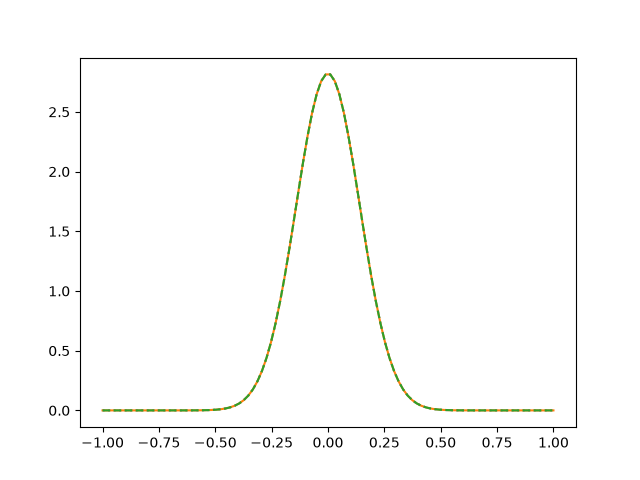

In [19]:
%matplotlib widget
from matplotlib.animation import FuncAnimation

def update(k):    
    global a, dt, t0, x, D2, AA, x0

    # time-update
    #da = dt * np.polynomial.chebyshev.chebder(a, m=2)
    #da = dt * D2@a
    #a[:-2] = a[:-2] + da
    a = AA@a

    # boundary condition
    #a[-2] = -np.sum(a[:-2:2])
    #a[-1] = -np.sum(a[1:-2:2])
    a = P@a
    
    poly = np.polynomial.chebyshev.Chebyshev(a)
    dat.set_ydata(poly(x))
    t = t0 + (k+1)*dt
    dat2.set_ydata(greens(x, x0, t, 1))
    ax.set_title('t=%lg' % (t,))

    return dat, dat2
    
# initial condition
n = 100
x = np.linspace(-1,1,n,endpoint=True)
dx = x[1]-x[0]
t0 = 0.01
x0 = 0.0
Tinit = greens(x, x0, t0, 1)

tend = 100*t0
dt = 1e-3
niter = int((tend-t0)/dt)
dt = (tend-t0)/niter

n_mode = 32  # assumed to be even number
a = np.polynomial.chebyshev.chebfit(x, Tinit, n_mode-1)
# This matrix sets the last two coefficients as needed for the boundary conditions
#a[-2] = -np.sum(a[:-1:2])   # sum of even coefficients
#a[-1] = -np.sum(a[1:-2:2])  # sum of odd coefficients
P = np.eye(n_mode)
P[-2, :] = 0
P[-2, :-2:2] = -1
P[-1, :] = 0
P[-1, 1:-2:2] = -1
a = P@a

# This is the matrix equivalent of taking the second derivative
D2 = np.column_stack([np.polynomial.chebyshev.chebder(np.eye(n_mode)[:, j], m=2) for j in range(n_mode)])
# Pad it with two zero rows
D2_full = np.zeros((n_mode, n_mode))
D2_full[:-2,:] = D2
# Construct the update matrix for backward Euler
AA = np.eye(n_mode) - dt * D2_full @ P
AA = np.linalg.inv(AA)

# Initial plot
plt.close()
fig, ax = plt.subplots()
dat2, = ax.plot(x, Tinit, ':')
poly = np.polynomial.chebyshev.Chebyshev(a)
dat, = ax.plot(x, poly(x))
ax.plot(x, Tinit,'--')

ani = FuncAnimation(fig, update, frames=niter, interval=10, repeat=False)